# Full Autoencoder (AE) Pipeline — Fashion Product Images Dataset

**Dataset:** `paramaggarwal/fashion-product-images-dataset`

**Role of the Autoencoder:**
- Denoise / clean product images
- Anomaly detection: flag corrupted / mismatched images (high reconstruction error)
- Feature extraction: compress images into embeddings for similarity search
- Metrics: MSE, PSNR, SSIM

Install dependencies first (uncomment the cell below if running fresh):


In [1]:
# !pip install kagglehub[pandas-datasets] tensorflow scikit-image matplotlib pandas numpy pillow --quiet

## 0. Imports & Config

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

import kagglehub
from kagglehub import KaggleDatasetAdapter

In [3]:
IMG_SIZE = 128          # resize all images to IMG_SIZE x IMG_SIZE (was 64 -> blur fix)
CHANNELS = 3
LATENT_DIM = 512        # was 256 -> 192:1 compression was too aggressive, causing blur/muddy color even after training stabilized
BATCH_SIZE = 64
EPOCHS = 120             # was 60 -> loss curve was still steadily decreasing at epoch 60, hadn't converged yet
NOISE_FACTOR = 0.05     # for the denoising variant (was 0.2 -> was over-smoothing output)
ANOMALY_PERCENTILE = 95 # top 5% reconstruction error flagged as anomalies
MAX_IMAGES = 5000       # cap for a fast run; raise/remove for full dataset run

DATASET_SLUG = "paramaggarwal/fashion-product-images-dataset"

LEARNING_RATE = 1e-4   # was implicit 1e-3 (Adam default) -> too aggressive, caused dead-ReLU collapse
USE_COMBINED_LOSS = True  # flip to False to isolate whether the SSIM term is at fault

# --- Loss rebalance (fixes color-shift) ---
# SSIM is locally tolerant of small brightness/contrast shifts -- great for
# structure, bad for exact hue/intensity. At 0.5/0.5 its gradient was pulling
# reconstructions toward "structurally similar but slightly off-color" outputs.
# Weighting MSE much higher keeps SSIM's edge-preserving benefit without
# letting it dominate absolute color accuracy.
MSE_WEIGHT = 0.8
SSIM_WEIGHT = 0.2


## 1. Load Metadata (`styles.csv`) via kagglehub

In [4]:
def load_metadata():
    """Loads the styles.csv metadata table (product id -> category etc.)."""
    # Download the dataset to get the local path
    dataset_path = kagglehub.dataset_download(DATASET_SLUG)
    print(f"Dataset downloaded to: {dataset_path}")

    csv_file_path = None

    # Search for styles.csv within the downloaded directory tree
    for root, dirs, files in os.walk(dataset_path):
        if "styles.csv" in files:
            csv_file_path = os.path.join(root, "styles.csv")
            break

    if not csv_file_path:
        raise FileNotFoundError(f"styles.csv not found anywhere under {dataset_path}")

    # Load the CSV using pandas
    df = pd.read_csv(
        csv_file_path,
        on_bad_lines="skip",
    )
    print("Metadata shape:", df.shape)
    return df

df = load_metadata()
df.head()

100%|██████████| 23.1G/23.1G [04:27<00:00, 92.6MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/paramaggarwal/fashion-product-images-dataset/versions/1
Metadata shape: (44424, 10)


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [5]:
def get_dataset_root():
    """
    kagglehub caches the raw dataset files locally (images/ folder etc).
    dataset_download gives us the root path so we can walk the images directory
    directly (styles.csv only gives metadata, not pixel access).
    """
    path = kagglehub.dataset_download(DATASET_SLUG)
    print("Dataset root:", path)
    return path

dataset_root = get_dataset_root()

Dataset root: /root/.cache/kagglehub/datasets/paramaggarwal/fashion-product-images-dataset/versions/1


## 2. Build Image Array From Disk

In [6]:
def build_image_array(df, dataset_root, max_images=MAX_IMAGES):
    """
    Loads product images referenced by df['id'], resizes to IMG_SIZE,
    normalizes to [0,1], and returns (images_array, ids_used, failed_ids).
    Skips any file that fails to load (corrupted -> logged, not crashed on).
    """

    images_dir = None
    # Search for the 'images' directory within the downloaded dataset's root
    for root, dirs, files in os.walk(dataset_root):
        if 'images' in dirs:
            images_dir = os.path.join(root, 'images')
            break

    if not images_dir:
        print(f"Error: 'images' directory not found anywhere under {dataset_root}")
        return np.array([], dtype="float32"), [], df["id"].astype(str).tolist()[:max_images]

    images, ids_used, failed_ids = [], [], []

    ids = df["id"].astype(str).tolist()[:max_images]
    for pid in ids:
        fpath = os.path.join(images_dir, f"{pid}.jpg")
        if not os.path.exists(fpath):
            failed_ids.append(pid)
            continue
        try:
            img = load_img(fpath, target_size=(IMG_SIZE, IMG_SIZE))
            arr = img_to_array(img) / 255.0
            images.append(arr)
            ids_used.append(pid)
        except Exception:
            failed_ids.append(pid)

    print(f"Loaded {len(images)} images successfully, {len(failed_ids)} failed/missing.")
    return np.array(images, dtype="float32"), ids_used, failed_ids

images, ids_used, failed_ids = build_image_array(df, dataset_root)
images.shape

Loaded 5000 images successfully, 0 failed/missing.


(5000, 128, 128, 3)

In [7]:
# Train / val split
n = len(images)
split = int(n * 0.9)
x_train, x_val = images[:split], images[split:]
print("Train:", x_train.shape, "Val:", x_val.shape)

Train: (4500, 128, 128, 3) Val: (500, 128, 128, 3)


## 3. Autoencoder Model (Conv Encoder → Latent → Conv Decoder)

In [8]:
def combined_loss(y_true, y_pred):
    """MSE + SSIM loss. Pure MSE alone rewards blurry averages; adding an
    SSIM term pushes the model to preserve edges/structure -> sharper output.
    Weighted MSE_WEIGHT/SSIM_WEIGHT (not 50/50) so SSIM's tolerance of small
    brightness/contrast shifts doesn't win out over color accuracy -- this
    was the fix for reconstructions coming out a visibly different shade
    than the original."""
    mse = tf.reduce_mean(tf.square(y_true - y_pred))
    ssim_term = 1 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return MSE_WEIGHT * mse + SSIM_WEIGHT * ssim_term


def conv_block(x, filters, strides, transpose=False):
    """Conv/Deconv -> BatchNorm -> LeakyReLU.
    BatchNorm keeps activations from saturating in the first few training
    steps, and LeakyReLU (unlike plain ReLU) still passes a small gradient
    for negative pre-activations -- together these are the fix for the
    dead-ReLU collapse we saw (loss frozen bit-for-bit from epoch 2 on)."""
    Layer = layers.Conv2DTranspose if transpose else layers.Conv2D
    x = Layer(filters, 3, strides=strides, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.1)(x)
    return x


def build_autoencoder(img_size=IMG_SIZE, channels=CHANNELS, latent_dim=LATENT_DIM):
    # ---- Encoder ----
    # NOTE: only 3 stride-2 blocks now (was 4) -> encoder bottoms out at
    # 16x16 instead of 8x8 before the dense bottleneck. Less aggressive
    # spatial compression = less irrecoverable detail = less blur.
    # We also keep the 64x64 feature map ("skip") to hand to the decoder
    # directly, bypassing the dense bottleneck entirely for fine detail/color.
    encoder_input = layers.Input(shape=(img_size, img_size, channels), name="encoder_input")
    x = conv_block(encoder_input, 32, strides=2)   # 64x64
    skip = x                                        # stash for decoder skip connection
    x = conv_block(x, 64, strides=2)                # 32x32
    x = conv_block(x, 128, strides=2)               # 16x16
    x = conv_block(x, 256, strides=1)               # 16x16, extra detail layer
    shape_before_flatten = x.shape[1:]
    x = layers.Flatten()(x)
    latent = layers.Dense(latent_dim, activation="relu", name="embedding")(x)
    # Two outputs: `latent` is still the compressed embedding used later for
    # anomaly detection / similarity search. `skip` only feeds the decoder.
    encoder = Model(encoder_input, [latent, skip], name="encoder")

    # ---- Decoder ----
    decoder_latent_input = layers.Input(shape=(latent_dim,), name="decoder_latent_input")
    skip_input = layers.Input(shape=skip.shape[1:], name="decoder_skip_input")
    x = layers.Dense(int(np.prod(shape_before_flatten)), activation="relu")(decoder_latent_input)
    x = layers.Reshape(shape_before_flatten)(x)
    x = conv_block(x, 256, strides=1, transpose=True)   # 16x16, extra detail layer
    x = conv_block(x, 128, strides=2, transpose=True)   # 32x32
    x = conv_block(x, 64, strides=2, transpose=True)    # 64x64
    x = layers.Concatenate(name="skip_concat")([x, skip_input])  # inject encoder's 64x64 detail/color here
    x = conv_block(x, 32, strides=2, transpose=True)    # 128x128
    decoder_output = layers.Conv2D(channels, 3, activation="sigmoid", padding="same")(x)
    decoder = Model([decoder_latent_input, skip_input], decoder_output, name="decoder")

    # ---- Full Autoencoder ----
    autoencoder_input = layers.Input(shape=(img_size, img_size, channels))
    encoded_latent, encoded_skip = encoder(autoencoder_input)
    decoded = decoder([encoded_latent, encoded_skip])
    autoencoder = Model(autoencoder_input, decoded, name="autoencoder")

    # Lower LR + gradient clipping: the original run used Adam's default
    # lr=1e-3 with no clipping, which likely blew activations into the dead
    # zone within the first epoch (loss was frozen identically from epoch 2
    # through epoch 60 -- a classic dead-ReLU / zero-gradient signature).
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0)
    loss_fn = combined_loss if USE_COMBINED_LOSS else "mse"
    autoencoder.compile(optimizer=optimizer, loss=loss_fn)

    return autoencoder, encoder, decoder

autoencoder, encoder, decoder = build_autoencoder()
autoencoder.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder             │ [(None, 512),     │ 33,944,800 │ input_layer[0][0] │
│ (Functional)        │ (None, 64, 64,    │            │                   │
│                     │ 32)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder             │ (None, 128, 128,  │ 34,608,867 │ encoder[0][0],    │
│ (Functional)        │ 3)                │            │ encoder[0][1]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 68,553,667 (261.51 MB)

 Trainable params: 68,551,747 (261.50 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 4. Training (Denoising Autoencoder)

Trains as a **denoising** autoencoder: Gaussian noise is added to the inputs while the clean image
is used as the target. This gives you denoising behavior for free, on top of normal reconstruction.

In [9]:
def add_noise(images, noise_factor=NOISE_FACTOR):
    noisy = images + noise_factor * np.random.normal(size=images.shape)
    return np.clip(noisy, 0.0, 1.0).astype("float32")

def train_autoencoder(autoencoder, x_train, x_val, denoising=True, epochs=EPOCHS):
    if denoising:
        x_train_input = add_noise(x_train)
        x_val_input = add_noise(x_val)
    else:
        x_train_input = x_train
        x_val_input = x_val

    callbacks = [
        # Bail out immediately on NaN/Inf loss instead of burning epochs on a dead run
        tf.keras.callbacks.TerminateOnNaN(),
        # Loss was still steadily decreasing at epoch 60 last run -- give it more room
        # before cutting the LR (was patience=4) so we don't choke off real progress.
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-6, verbose=1),
        # Same reasoning -- longer patience (was 10) since we're now training for 120 epochs.
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1),
    ]

    history = autoencoder.fit(
        x_train_input, x_train,             # noisy/raw input -> clean target
        validation_data=(x_val_input, x_val),
        epochs=epochs,
        batch_size=BATCH_SIZE,
        shuffle=True,
        verbose=1,
        callbacks=callbacks,
    )
    return history

history = train_autoencoder(autoencoder, x_train, x_val, denoising=True, epochs=EPOCHS)


Epoch 1/120
71/71 ━━━━━━━━━━━━━━━━━━━━ 50s 403ms/step - loss: 0.2043 - val_loss: 0.2055 - learning_rate: 1.0000e-04
Epoch 2/120
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 136ms/step - loss: 0.0872 - val_loss: 0.1416 - learning_rate: 1.0000e-04
Epoch 3/120
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 137ms/step - loss: 0.0492 - val_loss: 0.0932 - learning_rate: 1.0000e-04
Epoch 4/120
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - loss: 0.0354 - val_loss: 0.0628 - learning_rate: 1.0000e-04
Epoch 5/120
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 139ms/step - loss: 0.0286 - val_loss: 0.0437 - learning_rate: 1.0000e-04
Epoch 6/120
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 142ms/step - loss: 0.0249 - val_loss: 0.0308 - learning_rate: 1.0000e-04
Epoch 7/120
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - loss: 0.0224 - val_loss: 0.0234 - learning_rate: 1.0000e-04
Epoch 8/120
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - loss: 0.0206 - val_loss: 0.0331 - learning_rate: 1.0000e-04
Epoch 9/120
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 153ms/step - loss: 0.0195 - v

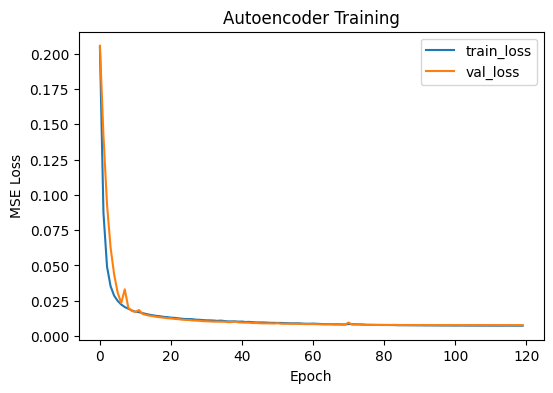

In [10]:
# Plot training curves
plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training")
plt.legend()
plt.show()

## 5. Reconstruct Full Set + Compute Metrics (MSE, PSNR, SSIM)

In [11]:
def compute_metrics(originals, reconstructions):
    mses, psnrs, ssims = [], [], []
    for orig, recon in zip(originals, reconstructions):
        mse_val = np.mean((orig - recon) ** 2)
        psnr_val = psnr(orig, recon, data_range=1.0)
        ssim_val = ssim(orig, recon, data_range=1.0, channel_axis=-1)
        mses.append(mse_val)
        psnrs.append(psnr_val)
        ssims.append(ssim_val)

    results = pd.DataFrame({"mse": mses, "psnr": psnrs, "ssim": ssims})
    print("--- Reconstruction Quality (aggregate) ---")
    print(results.mean())
    return results

reconstructions = autoencoder.predict(images, batch_size=BATCH_SIZE, verbose=0)
metrics_df = compute_metrics(images, reconstructions)
metrics_df.head()

--- Reconstruction Quality (aggregate) ---
mse      0.000620
psnr    32.982460
ssim     0.976403
dtype: float64


,mse,psnr,ssim
0,0.000922,30.352913,0.986345
1,0.000391,34.078756,0.983514
2,0.000382,34.180837,0.978534
3,0.000516,32.877133,0.974746
4,0.000513,32.902375,0.979403


## 6. Visualize Original vs Reconstructed

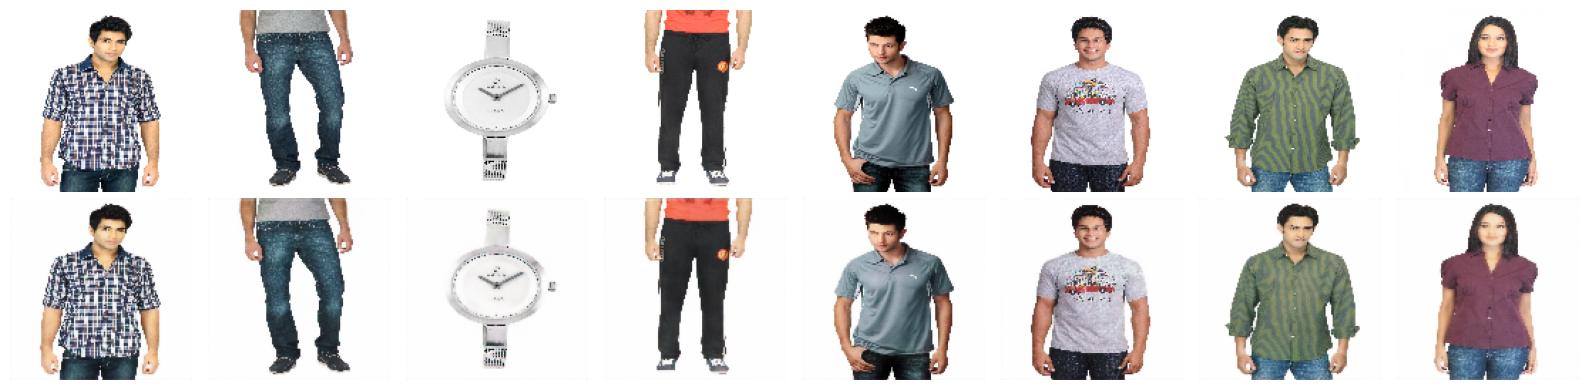

In [12]:
def plot_reconstructions(originals, reconstructions, n=8):
    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4))
    for i in range(n):
        axes[0, i].imshow(originals[i])
        axes[0, i].axis("off")
        axes[1, i].imshow(reconstructions[i])
        axes[1, i].axis("off")
    axes[0, 0].set_ylabel("Original", fontsize=10)
    axes[1, 0].set_ylabel("Reconstructed", fontsize=10)
    plt.tight_layout()
    plt.show()

plot_reconstructions(images, reconstructions)

## 6b. Show Only Clear Reconstructions (SSIM-Filtered)

5000 / 5000 images pass SSIM >= 0.75


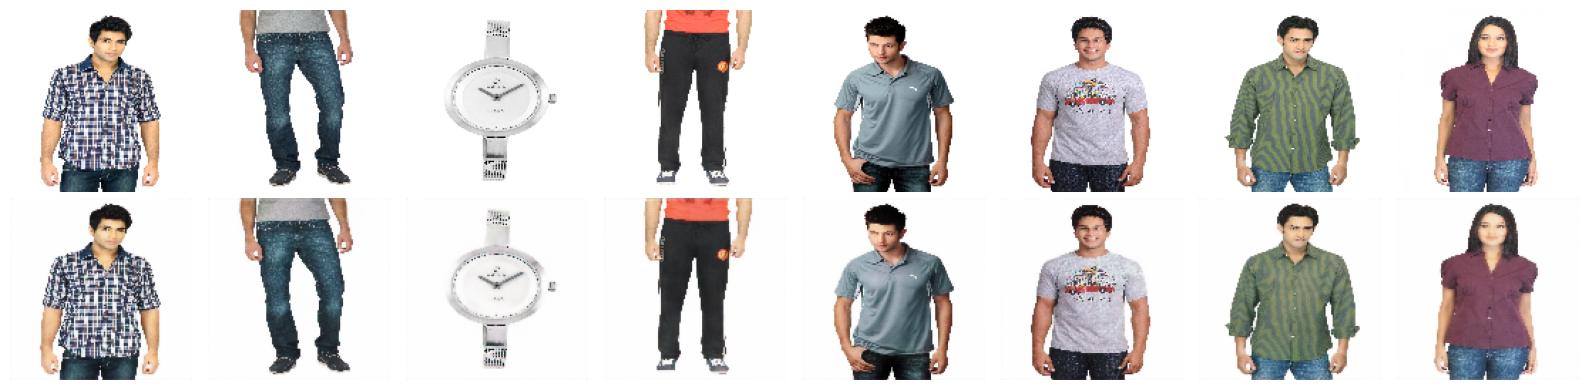

In [13]:
def plot_high_quality_reconstructions(originals, reconstructions, metrics_df, ssim_threshold=0.75, n=8):
    """Only display reconstructions whose SSIM against the original is >= ssim_threshold,
    i.e. only the images that came out clear/sharp, not the blurry ones."""
    good_idx = metrics_df[metrics_df["ssim"] >= ssim_threshold].index.tolist()
    print(f"{len(good_idx)} / {len(metrics_df)} images pass SSIM >= {ssim_threshold}")

    if len(good_idx) == 0:
        print("No images meet this threshold yet - lower ssim_threshold or retrain with combined_loss.")
        return

    selected = good_idx[:n]
    fig, axes = plt.subplots(2, len(selected), figsize=(2 * len(selected), 4))
    if len(selected) == 1:
        axes = axes.reshape(2, 1)
    for col, idx in enumerate(selected):
        axes[0, col].imshow(originals[idx]); axes[0, col].axis("off")
        axes[1, col].imshow(reconstructions[idx]); axes[1, col].axis("off")
    axes[0, 0].set_ylabel("Original", fontsize=10)
    axes[1, 0].set_ylabel("Reconstructed", fontsize=10)
    plt.tight_layout()
    plt.show()

# Uses metrics_df computed in section 5 (must run that cell first)
plot_high_quality_reconstructions(images, reconstructions, metrics_df, ssim_threshold=0.75, n=8)

## 7. Anomaly Detection (High Reconstruction Error → Flagged)

In [14]:
def flag_anomalies(metrics_df, ids_used, percentile=ANOMALY_PERCENTILE):
    threshold = np.percentile(metrics_df["mse"], percentile)
    metrics_df = metrics_df.copy()
    metrics_df["id"] = ids_used
    metrics_df["is_anomaly"] = metrics_df["mse"] > threshold
    n_flagged = metrics_df["is_anomaly"].sum()
    print(f"Anomaly threshold (MSE @ p{percentile}): {threshold:.5f}")
    print(f"Flagged {n_flagged} / {len(metrics_df)} images as anomalies/corrupted.")
    return metrics_df.sort_values("mse", ascending=False)

anomaly_df = flag_anomalies(metrics_df, ids_used)
anomaly_df.head(10)

Anomaly threshold (MSE @ p95): 0.00131
Flagged 250 / 5000 images as anomalies/corrupted.


,mse,psnr,ssim,id,is_anomaly
850,0.007707,21.130962,0.942176,2616,True
1471,0.007605,21.189041,0.953708,6447,True
4955,0.007320,21.354912,0.952806,6819,True
1645,0.007305,21.363649,0.953624,6820,True
1911,0.007160,21.450656,0.955606,6818,True
438,0.007076,21.501905,0.958068,1638,True
932,0.007076,21.501929,0.949274,2888,True
121,0.007017,21.538314,0.941130,2618,True
77,0.006961,21.573053,0.951825,2872,True
2853,0.006915,21.602200,0.931316,4974,True


## 8. Extract Embeddings for Similarity Search

In [9]:
def extract_embeddings(encoder, images, ids_used):
    # encoder now has two outputs: [latent_embedding, skip_feature_map].
    # We only want the latent vector for similarity search / anomaly use.
    embeddings, _skip = encoder.predict(images, batch_size=BATCH_SIZE, verbose=0)
    emb_df = pd.DataFrame(embeddings)
    emb_df.insert(0, "id", ids_used)
    print(f"Extracted embeddings: shape {embeddings.shape}")
    return emb_df, embeddings

emb_df, embeddings = extract_embeddings(encoder, images, ids_used)
emb_df.head()


NameError: name 'images' is not defined

In [10]:
def find_similar(query_idx, embeddings, ids_used, top_k=5):
    """Cosine similarity search over the embedding space."""
    query_vec = embeddings[query_idx]
    norm_embeddings = embeddings / (np.linalg.norm(embeddings, axis=1, keepdims=True) + 1e-8)
    norm_query = query_vec / (np.linalg.norm(query_vec) + 1e-8)
    sims = norm_embeddings @ norm_query
    top_indices = np.argsort(-sims)[1: top_k + 1]  # skip itself
    return [(ids_used[i], sims[i]) for i in top_indices]

example_matches = find_similar(0, embeddings, ids_used, top_k=5)
print(f"Top-5 similar products to id={ids_used[0]}: {example_matches}")

NameError: name 'embeddings' is not defined

In [11]:
def find_similar_by_category(query_id, df, embeddings_df, ids_used_all, embeddings_all, category_column='masterCategory', top_k=5):
    # 1. Get the category of the query product
    query_category = df.loc[df['id'] == int(query_id), category_column].iloc[0]
    print(f"Query product ID: {query_id}, Category: {query_category}")

    # 2. Filter products by the same category
    filtered_df = df[df[category_column] == query_category].copy()
    filtered_ids = filtered_df['id'].astype(str).tolist()

    # 3. Get the embeddings for the filtered products
    # Need to map filtered_ids back to their original index in embeddings_all
    # and then get the corresponding embeddings
    filtered_embeddings_indices = [ids_used_all.index(fid) for fid in filtered_ids if fid in ids_used_all]
    filtered_embeddings = embeddings_all[filtered_embeddings_indices]
    filtered_ids_for_search = [ids_used_all[idx] for idx in filtered_embeddings_indices]

    # Find the index of the query_id within the filtered_ids_for_search
    try:
        query_idx_in_filtered = filtered_ids_for_search.index(query_id)
    except ValueError:
        print(f"Query ID {query_id} not found in the filtered category. Cannot find similar products.")
        return []

    # 4. Perform similarity search on the filtered embeddings
    # The existing find_similar function is designed to work with a flat array of embeddings and corresponding IDs
    # We need to adjust it to work with the filtered set.
    query_vec_filtered = filtered_embeddings[query_idx_in_filtered]

    # Calculate cosine similarities
    norm_embeddings_filtered = filtered_embeddings / (np.linalg.norm(filtered_embeddings, axis=1, keepdims=True) + 1e-8)
    norm_query_filtered = query_vec_filtered / (np.linalg.norm(query_vec_filtered) + 1e-8)
    sims_filtered = norm_embeddings_filtered @ norm_query_filtered

    # Get top_k indices, skipping the query itself
    top_indices_filtered = np.argsort(-sims_filtered)

    # Filter out the query_id itself from the results
    results = []
    for idx in top_indices_filtered:
        if filtered_ids_for_search[idx] != query_id:
            results.append((filtered_ids_for_search[idx], sims_filtered[idx]))
        if len(results) == top_k:
            break

    return results

# Example usage:
query_example_id = ids_used[0] # Use the first ID from the loaded images
category_matches = find_similar_by_category(query_example_id, df, emb_df, ids_used, embeddings, category_column='masterCategory', top_k=5)
print(f"Top-5 similar products within the same category as id={query_example_id}: {category_matches}")

NameError: name 'ids_used' is not defined

### Reconstructed Images by Category

In [12]:
from IPython.display import display, Markdown

# Combine df and ids_used to get categories for processed images
processed_df = df[df['id'].astype(str).isin(ids_used)].copy()
processed_df = processed_df.set_index('id')

# Create a mapping from image ID to its index in the `images` and `reconstructions` arrays
id_to_idx = {id_str: idx for idx, id_str in enumerate(ids_used)}

# Get unique categories from the processed DataFrame
unique_categories = processed_df['masterCategory'].unique()

print(f"Displaying reconstructions for {len(unique_categories)} unique categories.")

# Iterate through each category and plot reconstructions
for category in unique_categories:
    display(Markdown(f"#### Category: {category}"))

    # Get IDs for the current category
    category_ids = processed_df[processed_df['masterCategory'] == category].index.astype(str).tolist()

    # Get indices of these IDs in the original images/reconstructions arrays
    category_indices = [id_to_idx[cid] for cid in category_ids if cid in id_to_idx]

    # Select up to 'n' (e.g., 8) random images from this category for plotting
    n_to_plot = 8
    if len(category_indices) > 0:
        selected_indices = np.random.choice(category_indices, min(n_to_plot, len(category_indices)), replace=False)

        # Extract selected original and reconstructed images
        selected_originals = images[selected_indices]
        selected_reconstructions = reconstructions[selected_indices]

        # Plot them using the existing function
        plot_reconstructions(selected_originals, selected_reconstructions, n=len(selected_indices))
    else:
        print(f"No images found for category: {category}")


NameError: name 'ids_used' is not defined

## 9. Save Artifacts

In [6]:
autoencoder.save("autoencoder_full.keras")
encoder.save("autoencoder_encoder.keras")
metrics_df.to_csv("reconstruction_metrics.csv", index=False)
anomaly_df.to_csv("anomaly_flags.csv", index=False)
emb_df.to_csv("embeddings.csv", index=False)

print("Saved: autoencoder_full.keras, autoencoder_encoder.keras, "
      "reconstruction_metrics.csv, anomaly_flags.csv, embeddings.csv")

NameError: name 'metrics_df' is not defined